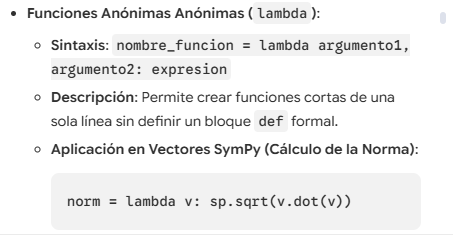
<br>
se usara la funcion landam que lo que hace es que le da nombre a una funcion , le da el parametro y que hara
<br>
<br>
el programa buscara encontrar los vectores
<br>
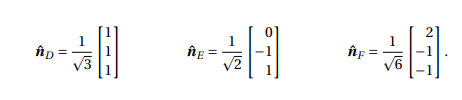
<br>
que son las coordenadas que nos servira para ubicar los esfuerzos dentro del plano pi sin sus componentes hidroestaticas
<br>
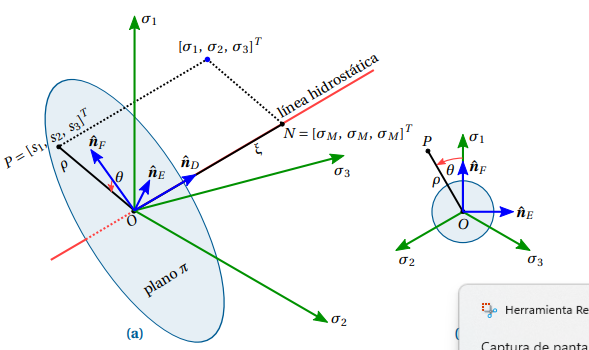

In [74]:
import sympy as sp

print("se crea una funcion llamada vector usando lambda")

#se crea la funcion para calcular la norma de un vector empleando la funcion lambda

#norma=lambda vector:(((vector[0])**2)+((vector[1])**2)+((vector[2])**2))**(1/2) ##nsimplyfy para que me den numero racionales
#la anterior forma nos dara los resultados en decimales, usando sp.sqrt nos daran las raices
norma=lambda vector:(sp.sqrt(((vector[0])**2)+((vector[1])**2)+((vector[2])**2)))
print("definimos una variable p y le dijimos que es positiva")

#creo un vector que describe la linea hidroestatica y lo vuelvo unitario
p=sp.symbols("P", positive=True)  ## aca le metemos un simbolo y dijmos que es verdad que es positivo
display(p)

print("se crea el vector que describe la linea hidroestatica ")
Vectornd=sp.Matrix([p,p,p])
display(Vectornd)

print("lo normalizo")

vectornd_unitario=(Vectornd/norma(Vectornd))

display(vectornd_unitario)
print("este vector es Nd unitario que me describe la linea hidroestatica")
print("-------------------------------------------------------------------------------------------------------")
print("ahora se buscara hallar un vector perpendicular a Nd para ello usaremos el producto cruz de un vector no paralelo cualsea en el espacio")
print("y aremos el producto cruz con Nd")
print("vector escogido: ")
vectorx=sp.Matrix([1,0,0])
display(vectorx)
print("hacemos producto cruz, vector escogido x nd y luego lo normalizamos")
productocruz1=vectorx.cross(vectornd_unitario)
display(productocruz1)

Ne=productocruz1/norma(productocruz1)
display(Ne)
print("este sera el vector Ne QUE ES PERPENDICULAR A Nd")
print("-------------------------------------------------------------------------------------------------------")
print("ahora hare el producto cruz entre Nd y Ne para hallar el vector unitario Nf, este vector ya estara normalizado debido a que ")
print("Nd Y Ne son perpendiculares")
Nf=vectornd_unitario.cross(Ne)
display(Nf)

print("-------------------------------------------------------------------------------------------------------")

se crea una funcion llamada vector usando lambda
definimos una variable p y le dijimos que es positiva


P

se crea el vector que describe la linea hidroestatica 


Matrix([
[P],
[P],
[P]])

lo normalizo


...

Matrix([
[         0],
[-sqrt(3)/3],
[ sqrt(3)/3]])

Matrix([
[         0],
[-sqrt(2)/2],
[ sqrt(2)/2]])

este sera el vector Ne QUE ES PERPENDICULAR A Nd
-------------------------------------------------------------------------------------------------------
ahora hare el producto cruz entre Nd y Ne para hallar el vector unitario Nf, este vector ya estara normalizado debido a que 
Nd Y Ne son perpendiculares


Matrix([
[ sqrt(6)/3],
[-sqrt(6)/6],
[-sqrt(6)/6]])

-------------------------------------------------------------------------------------------------------


AHORA SE CALCULARAN LAS SIGUIENTES EXPRESIONES
<br>
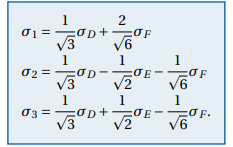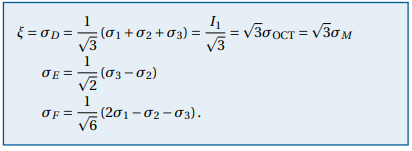
<br>
PARA ELLO USAREMOS LA FORMULAS DE CAMBIO DE BASE PARA VECTORES :
<br>
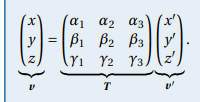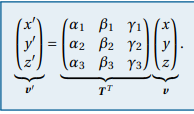

In [79]:
#cambiaremos de base primero defio las variables
sigma1=sp.symbols("sigma_1")
sigma2=sp.symbols("sigma_2")
sigma3=sp.symbols("sigma_3")

sigmad=sp.symbols("sigma_D")
sigmae=sp.symbols("sigma_E")
sigmaf=sp.symbols("sigma_F")

##defino los vectores
vvisual=sp.Matrix([sigma1,sigma2,sigma3])
vprimavisual=sp.Matrix([sigmad,sigmae,sigmaf])

#defino la matrix transpuesta
transformacion=sp.Matrix(transformacion.hstack(vectornd_unitario,Ne,Nf))
display(transformacion,vvisual,vprimavisual)
#otra manera
#T=transformacion.hstack(vectornd_unitario,Ne,Nf)
#display(T)

print("-----------------------------------------------------------------------------------------------")
print("ahora hago el cambio de base de sigmad,e,f a sigma1,2,3")

operacion_vprima_a_v=(transformacion*vprimavisual)
display(operacion_vprima_a_v)
print("--------------------------------------------")

print("por lo cual:")
print("sigma 1 es:")
display(sp.simplify(operacion_vprima_a_v[0]))
print("sigma 2 es:")
display(sp.simplify(operacion_vprima_a_v[1]))
print("sigma 3 es:")
display(sp.simplify(operacion_vprima_a_v[2]))

print("--------------------------------------------------------------------------------------------")
print("ahora are lo mismo para que pasemos de sigma1,2,3 a sigmad,e,f")

operacion_v_a_vprima=((transformacion.transpose())*vvisual)
display(operacion_v_a_vprima)
print("--------------------------------------------")

print("por lo cual:")
print("sigma D es:")
display(sp.simplify(operacion_v_a_vprima[0]))
print("sigma E es:")
display(sp.simplify(operacion_v_a_vprima[1]))
print("sigma F es:")
display(sp.simplify(operacion_v_a_vprima[2]))


Matrix([
[sqrt(3)/3,          0,  sqrt(6)/3],
[sqrt(3)/3, -sqrt(2)/2, -sqrt(6)/6],
[sqrt(3)/3,  sqrt(2)/2, -sqrt(6)/6]])

Matrix([
[sigma_1],
[sigma_2],
[sigma_3]])

Matrix([
[sigma_D],
[sigma_E],
[sigma_F]])

-----------------------------------------------------------------------------------------------
ahora hago el cambio de base de sigmad,e,f a sigma1,2,3


Matrix([
[                    sqrt(3)*sigma_D/3 + sqrt(6)*sigma_F/3],
[sqrt(3)*sigma_D/3 - sqrt(2)*sigma_E/2 - sqrt(6)*sigma_F/6],
[sqrt(3)*sigma_D/3 + sqrt(2)*sigma_E/2 - sqrt(6)*sigma_F/6]])

...

sqrt(3)*(sigma_1 + sigma_2 + sigma_3)/3

sigma E es:


sqrt(2)*(-sigma_2 + sigma_3)/2

sigma F es:


sqrt(6)*(2*sigma_1 - sigma_2 - sigma_3)/6